# 03. Scenario 2 — "My overseas transfer has not arrived" (tool retry loop)

The second support scenario. This time the question contains enough detail (transfer reference and amount), but **the first tool returns a system error (tool_error)**. The agent reads the error at D6 (tool-result review), decides `try_alternative`, and runs the recursive loop that **retries with a different tool**.

Expected path:
```
D1 -> D2(transfers) -> D5(info_sufficient) -> D3(track_transfer) -> tool_error
-> D6(try_alternative) -> D3(alternative tool, failed one excluded) -> success -> D6(goal_met)
-> summary -> D7(no_risk) -> D4(resolve) -> final reply
```

This is the everyday "transient failure -> automatic recovery" flow of production systems. With the retry loop the decision count grows to 9, which makes the cumulative effect of decision latency easier to see.


In [1]:
import os
os.environ["DMWS_LANG"] = "en"   # localize helper output/graph captions (set BEFORE importing ws_common)
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # ws_common path (relative inside the repo)
import ws_common as W
graphs, client = W.make_graphs()
sc = W.scenario(2)
print("Scenario:", sc["title"])
print("Customer question:", sc["question"])
print("script (pre-set for reproducibility):", sc["script"])   # tool_outcomes: [tool_error, success]


Scenario: System error -> tool retry loop
Customer question: The overseas transfer I sent yesterday afternoon has not reached the recipient yet. Reference number TR-20261026-8841, amount USD 2,000. Please check what happened.
script (pre-set for reproducibility): {'vague': False, 'clarify_reply': None, 'no_info_reply': "That's all the information I have right now.", 'tool_outcomes': ['tool_error', 'success'], 'risk_flag': False, 'kyc_result': None}


## Where this scenario sits in the full workflow

The path this scenario takes (red borders): straight to the tool with no clarification, but the first tool fails, so the **self-loop on tool_step (retry)** runs once. Watch the same node execute twice in the STEP output.

Assigned team (red box): **transfers (transfers/remittance)** — tracking an overseas remittance, handled with transfers team tools (track_transfer etc.).
> Note: this diagram is not auto-generated from the running LangGraph; it is a **visualization-only drawing** rendered from the caption dictionaries in `ws_common.py`, keyed by node name (details: `[EN]_01_build_agent.ipynb`).


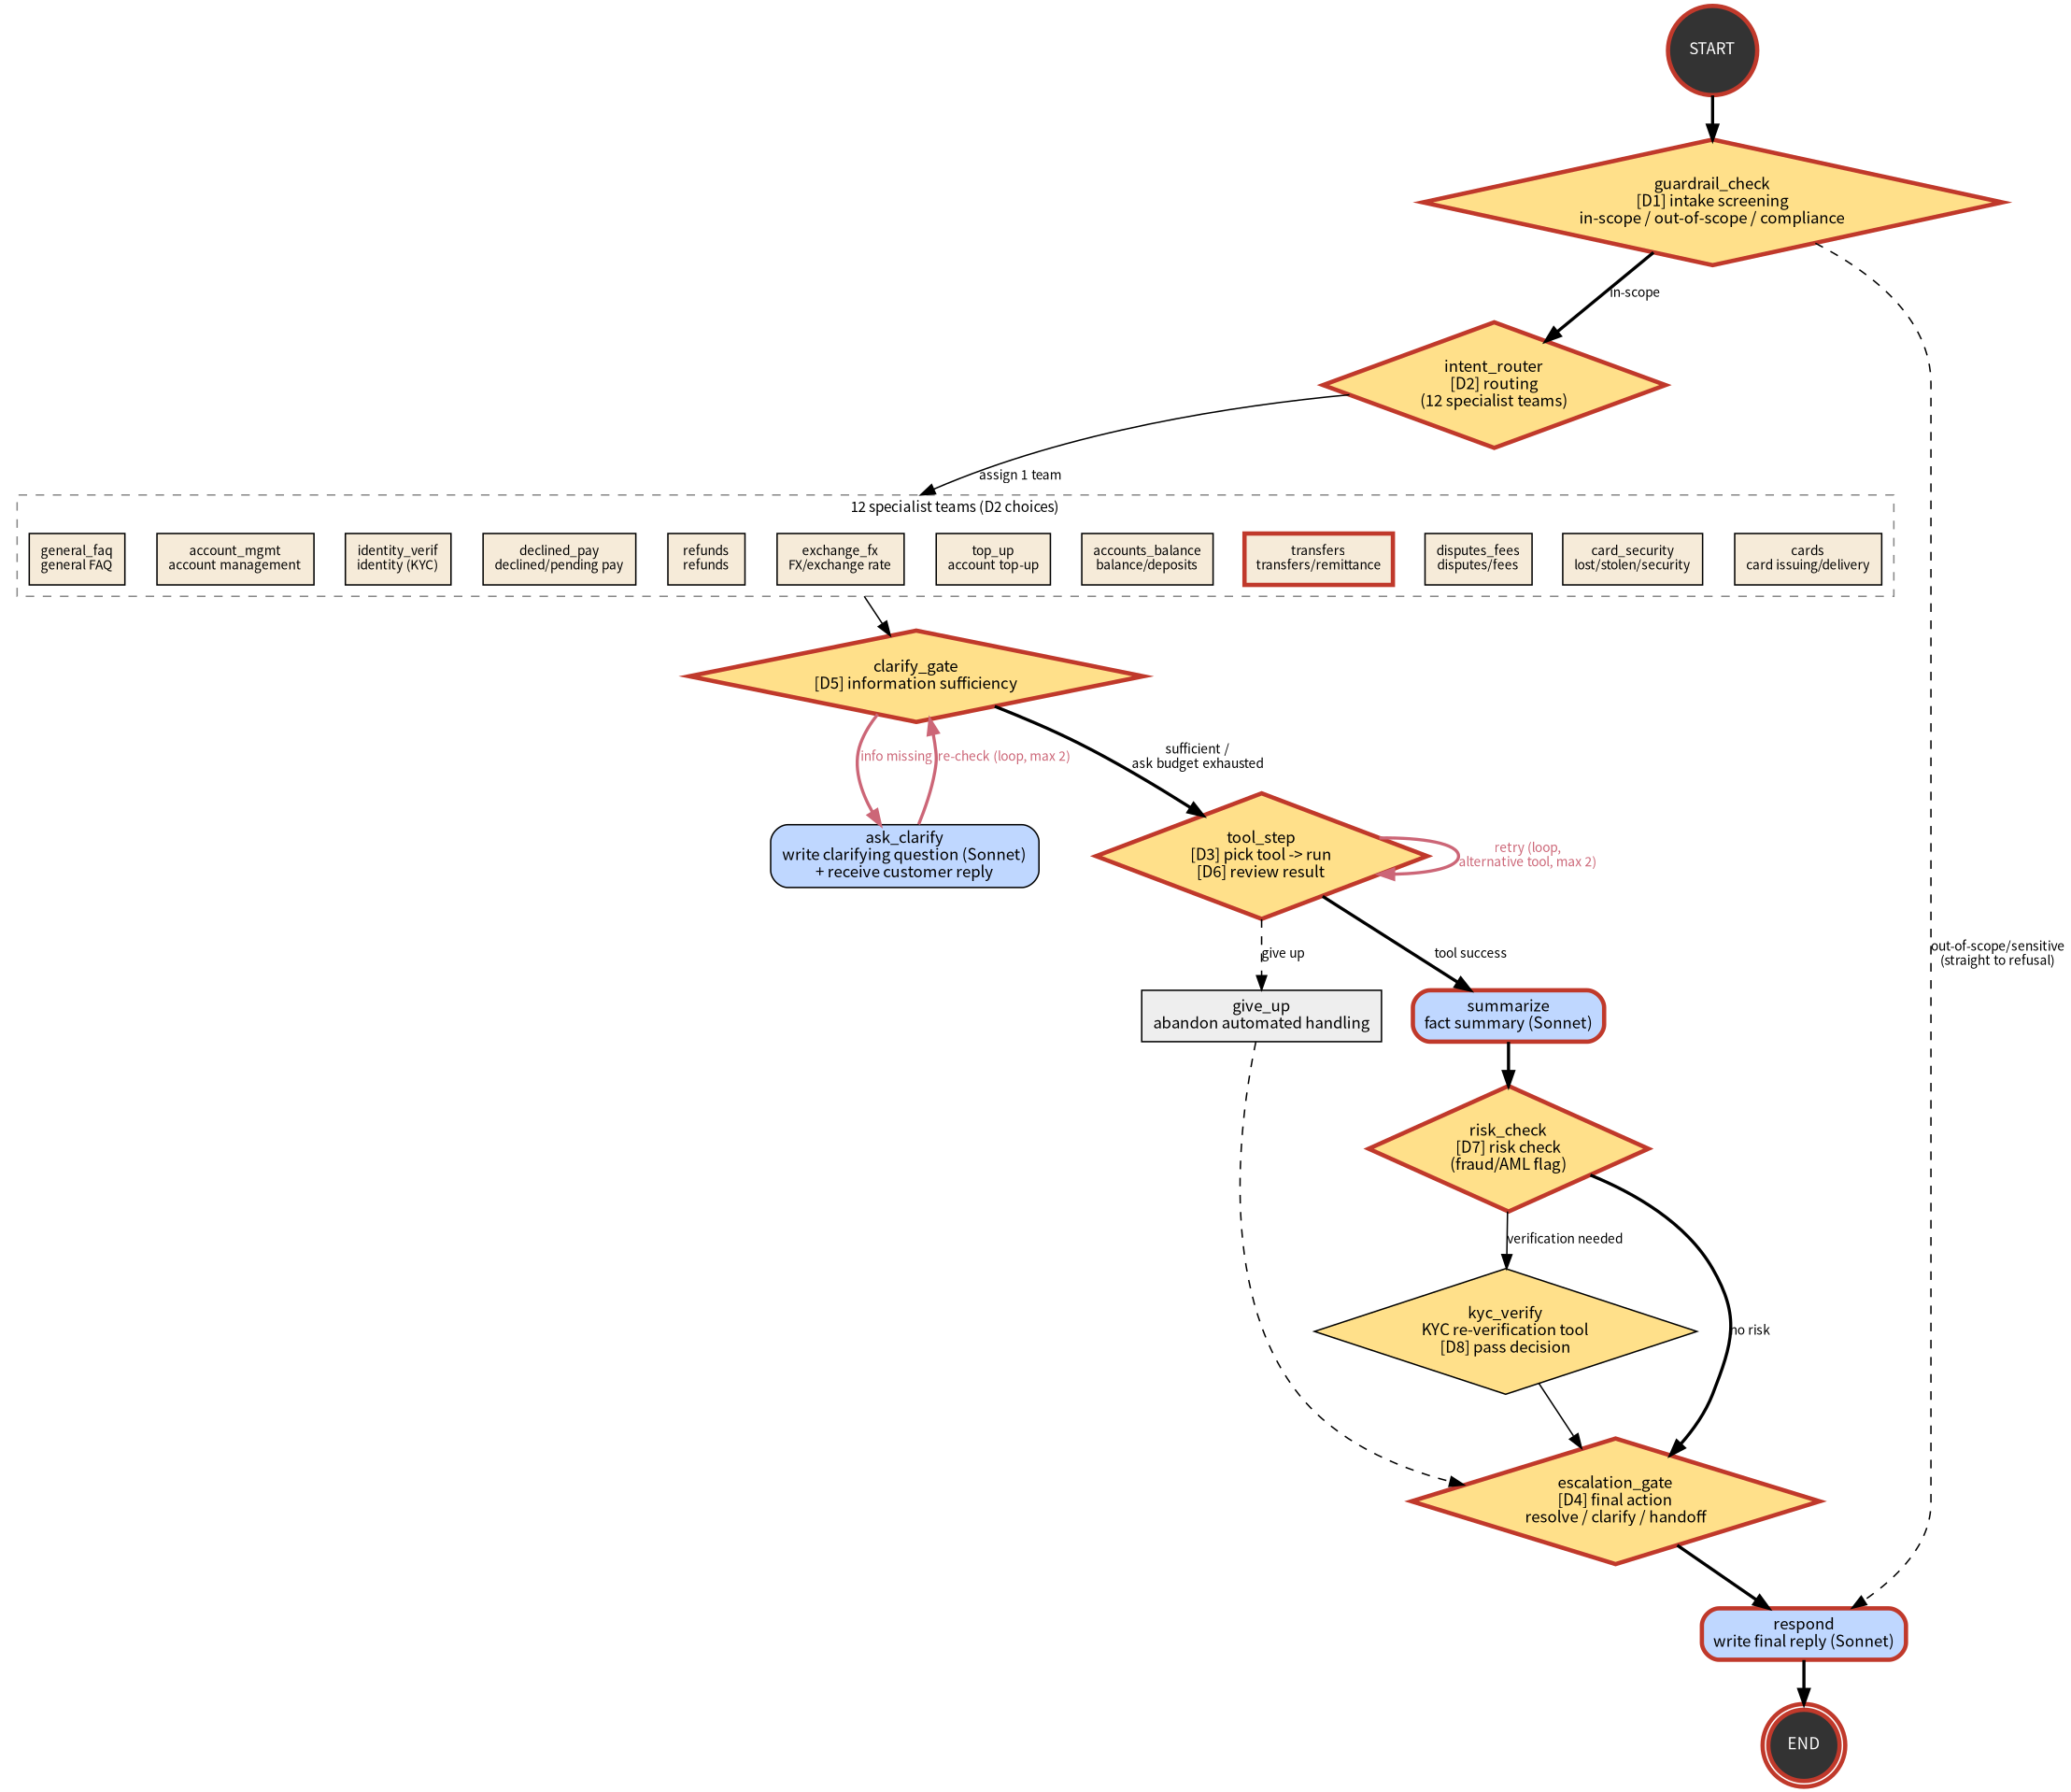

In [2]:
W.draw_graph(highlight=W.scenario_path(2), show_teams=True, width=760)

## (1) Run with Haiku 4.5 decisions

In the STEP output, confirm that tool_step appears **twice** (failure -> retry with an alternative tool), and that the second D3 decision receives the "Already tried (failed)" information.


In [3]:
res_haiku = W.run_verbose(graphs["Haiku"], sc["question"], sc["script"], "Haiku")


[Haiku] customer: The overseas transfer I sent yesterday afternoon has not reached the recipient yet. Reference number TR-20261026-8841, amount USD 2,000. Please check what happened.



STEP 1 ▶ guardrail_check — D1 intake screening: in-scope / out-of-scope / compliance
      decision[D1] -> in_scope   (813ms)



STEP 2 ▶ intent_router — D2 routing: pick one of 12 specialist teams
      decision[D2] -> transfers   (562ms)



STEP 3 ▶ clarify_gate — D5 sufficiency check: can we act now, or must we ask back?
      decision[D5] -> info_sufficient   (550ms)



STEP 4 ▶ tool_step — D3 tool choice -> run tool -> D6 result review (done/retry/give up)
      decision[D3] -> track_transfer   (565ms)
      tool run: track_transfer   (0.0ms)
      decision[D6] -> try_alternative   (590ms)



STEP 5 ▶ tool_step — D3 tool choice -> run tool -> D6 result review (done/retry/give up)
      decision[D3] -> transfer_info   (542ms)
      tool run: transfer_info   (0.0ms)
      decision[D6] -> goal_met   (555ms)



STEP 6 ▶ summarize — Sonnet condenses the tool result into customer-facing facts
      generate (Sonnet 4.5)   (4,672ms)
      summary (first line): Based on the tool result provided, I cannot extract specific resolution facts ab



STEP 7 ▶ risk_check — D7 risk check: fraud/AML monitoring flag present?
      decision[D7] -> no_risk   (552ms)



STEP 8 ▶ escalation_gate — D4 final action: resolve / clarify / human handoff
      decision[D4] -> human_handoff   (608ms)



STEP 9 ▶ respond — Sonnet writes the final customer reply
      generate (Sonnet 4.5)   (4,449ms)
      --- final reply ---
      Thank you for contacting us regarding your overseas transfer TR-20261026-8841 for USD 2,000.
      
      I understand your concern about the payment not yet reaching the recipient. International transfers can sometimes take 1-5 business days depending on the destination country and correspondent banks involved.
      
      I'm escalating your case to our International Payments team who have access to specialized tracking systems. They will investigate the current status of your transfer and contact you within 4 business hours via your registered email or phone number.
      
      Please keep your reference number TR-20261026-8841 handy for their call.
      
      We apologize for any inconvenience and appreciate your patience.

>>> [Haiku] 9 decisions, total 5,337ms | generation 9,121ms | e2e 14,466ms


## (2) Run with SGLang (Qwen3-VL-8B) decisions


In [4]:
res_sglang = W.run_verbose(graphs["SGLang"], sc["question"], sc["script"], "SGLang")


[SGLang] customer: The overseas transfer I sent yesterday afternoon has not reached the recipient yet. Reference number TR-20261026-8841, amount USD 2,000. Please check what happened.

STEP 1 ▶ guardrail_check — D1 intake screening: in-scope / out-of-scope / compliance
      decision[D1] -> in_scope   (54ms, confidence 1.000)

STEP 2 ▶ intent_router — D2 routing: pick one of 12 specialist teams
      decision[D2] -> transfers   (35ms, confidence 1.000)

STEP 3 ▶ clarify_gate — D5 sufficiency check: can we act now, or must we ask back?
      decision[D5] -> info_sufficient   (35ms, confidence 1.000)



STEP 4 ▶ tool_step — D3 tool choice -> run tool -> D6 result review (done/retry/give up)
      decision[D3] -> track_transfer   (36ms, confidence 1.000)
      tool run: track_transfer   (0.0ms)
      decision[D6] -> try_alternative   (36ms, confidence 1.000)



STEP 5 ▶ tool_step — D3 tool choice -> run tool -> D6 result review (done/retry/give up)
      decision[D3] -> transfer_info   (37ms, confidence 1.000)
      tool run: transfer_info   (0.0ms)
      decision[D6] -> goal_met   (36ms, confidence 0.820)



STEP 6 ▶ summarize — Sonnet condenses the tool result into customer-facing facts
      generate (Sonnet 4.5)   (5,173ms)
      summary (first line): Based on the tool result provided, I cannot extract specific resolution facts ab

STEP 7 ▶ risk_check — D7 risk check: fraud/AML monitoring flag present?
      decision[D7] -> no_risk   (45ms, confidence 1.000)

STEP 8 ▶ escalation_gate — D4 final action: resolve / clarify / human handoff
      decision[D4] -> clarify   (36ms, confidence 1.000)



STEP 9 ▶ respond — Sonnet writes the final customer reply
      generate (Sonnet 4.5)   (4,446ms)
      --- final reply ---
      Thank you for contacting us about your international transfer.
      
      To investigate the status of your transfer TR-20261026-8841, I need a bit more information:
      
      1. **Recipient's bank name and country** - Where was the money being sent?
      2. **Payment method used** - Was this a SWIFT transfer, or another method?
      3. **Account you sent from** - Which of your accounts did the USD 2,000 debit from?
      
      International transfers can take 1-5 business days depending on the destination country and correspondent banks involved. With these details, I can check the specific status and provide you with an accurate update.

>>> [SGLang] 9 decisions, total 349ms | generation 9,619ms | e2e 9,977ms


## (3) Execution time comparison


In [5]:
W.compare(res_haiku, res_sglang)

| metric | Haiku | SGLang | ratio(Haiku/SGLang) |
|---|---:|---:|---:|
| decisions | 9 | 9 | |
| **decision latency total** | **5,337ms** | **349ms** | **15.3x** |
| generation (LLM) latency | 9,121ms | 9,619ms | **0.9x** |
| e2e | 14,466ms | 9,977ms | **1.4x** |

**decision-layer speedup: 15.3x** (e2e saved 4,489ms)

**per-decision latency**

| node | decision | Haiku | SGLang | ratio | label |
|---|---|---:|---:|---:|---|
| guardrail_check | D1 | 813ms | 54ms | **15.1x** | in_scope (same) |
| intent_router | D2 | 562ms | 35ms | **15.9x** | transfers (same) |
| clarify_gate | D5 | 550ms | 35ms | **15.8x** | info_sufficient (same) |
| tool_select | D3 | 565ms | 36ms | **15.6x** | track_transfer (same) |
| tool_review | D6 | 590ms | 36ms | **16.5x** | try_alternative (same) |
| tool_select | D3 | 542ms | 37ms | **14.7x** | transfer_info (same) |
| tool_review | D6 | 555ms | 36ms | **15.4x** | goal_met (same) |
| risk_check | D7 | 552ms | 45ms | **12.3x** | no_risk (same) |
| escalation_gate | D4 | 608ms | 36ms | **16.8x** | Haiku=human_handoff / SGLang=clarify |

**What to look for**
- D6 is a decision that **reads the tool's JSON result and judges the situation** — harder than classification, yet check whether both backends reached the same conclusions (try_alternative -> goal_met).
- With 9 decisions, the Haiku arm's cumulative decision time reaches 5-6 seconds. This is why the decision layer is worth more the more loops an agent has.
- Next: `[EN]_04_scenario3_risk_kyc.ipynb` — the fraud-monitoring flag and the KYC re-verification sub-flow.
